 ЛАБОРАТОРНАЯ РАБОТА № 3.3: МЕТОД НАИМЕНЬШИХ КВАДРАТОВ (МНК)

-----------------------------------------------------------------------------------------------
1. ИСХОДНЫЕ ТАБЛИЧНЫЕ ДАННЫЕ
-----------------------------------------------------------------------------------------------
i    | x_i              | y_i             
-----------------------------------------------------------------------------------------------
0    | -1.0000          | -0.4597         
1    | 0.0000           | 1.0000          
2    | 1.0000           | 1.5403          
3    | 2.0000           | 1.5839          
4    | 3.0000           | 2.0100          
5    | 4.0000           | 3.3464          

-----------------------------------------------------------------------------------------------
2. ПОСТРОЕНИЕ ПРИБЛИЖАЮЩИХ МНОГОЧЛЕНОВ P_1(x), P_2(x), P_3(x)
-----------------------------------------------------------------------------------------------

[Многочлен P_1(x) (степень m = 1)]:
  P_1(x) = 0.556165 +0.63154

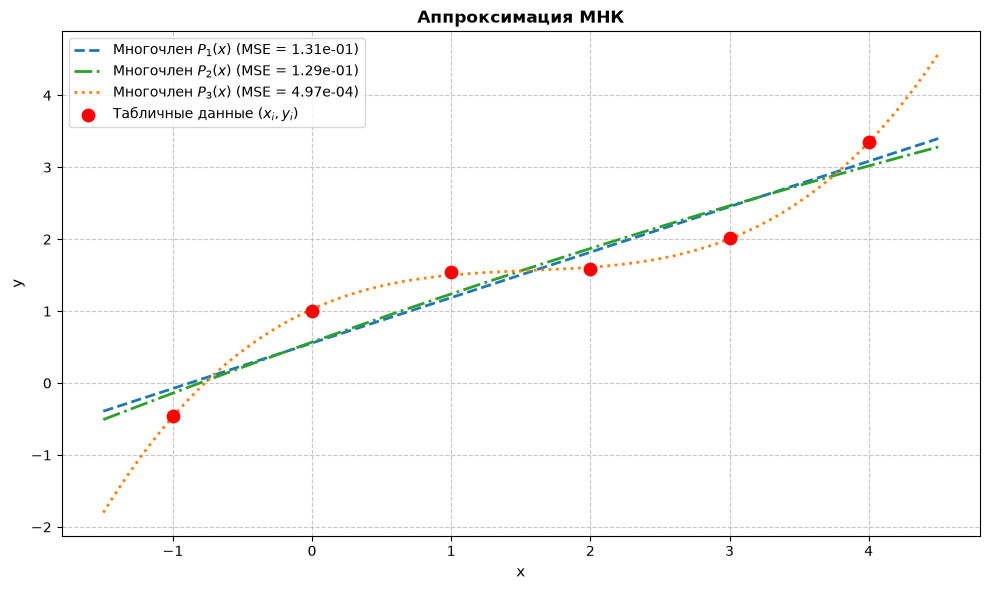

In [1]:
import math
import os
import sys
import numpy as np
%matplotlib inline
import matplotlib.pyplot as plt
from fractions import Fraction

sys.path.append(os.path.abspath('..'))

from lab1.lab_1_1_LU import lu_decomposition, solve_lu


class LeastSquaresTask:
    
    def __init__(self):

        
        self.nodes = [-1.0, 0.0, 1.0, 2.0, 3.0, 4.0]
        self.y_vals = [-0.4597, 1.0000, 1.5403, 1.5839, 2.0100, 3.3464]


def build_normal_system(nodes, y_vals, m):
    """Строит матрицу A и вектор правой части B"""

    A = [[0.0] * (m + 1) for _ in range(m + 1)]
    B = [0.0] * (m + 1)
    
    for i in range(m + 1):
        for j in range(m + 1):
            A[i][j] = sum(x ** (i + j) for x in nodes)
        B[i] = sum(y * (x ** i) for x, y in zip(nodes, y_vals))
        
    return A, B


def solve_least_squares(nodes, y_vals, m):
    """Решает систему МНК"""

    A, B = build_normal_system(nodes, y_vals, m)
    
    A_frac = [[Fraction(A[i][j]) for j in range(m + 1)] for i in range(m + 1)]
    B_frac = [Fraction(B[i]) for i in range(m + 1)]
    
    L, U, P, _ = lu_decomposition(A_frac)
    coeffs_frac = solve_lu(L, U, P, B_frac)
    
    coeffs = [float(c) for c in coeffs_frac]
    
    return coeffs, A, B


def evaluate_polynomial(coeffs, x):
    """Вычисляет значение P_m(x) в x"""

    return sum(c * (x ** i) for i, c in enumerate(coeffs))


def calculate_errors(coeffs, nodes, y_vals):
    """Вычисляет сумму квадратов невязо и среднеквадратичную ошибку (MSE)"""

    sq_errors = [(evaluate_polynomial(coeffs, x) - y) ** 2 for x, y in zip(nodes, y_vals)]
    S_sum = sum(sq_errors)
    mse = S_sum / len(nodes)
    return S_sum, mse


def format_polynomial(coeffs, deg):
    """Форматированный вывод явного вида аппроксимирующего многочлена P_m(x)"""

    terms = [f"{coeffs[0]:.6f}"]
    if deg >= 1:
        terms.append(f"{coeffs[1]:+.6f}*x")
    if deg >= 2:
        terms.append(f"{coeffs[2]:+.6f}*x^2")
    if deg >= 3:
        terms.append(f"{coeffs[3]:+.6f}*x^3")
    return " ".join(terms)


def plot_lsq_results(task, results):
    """Строит общий график табличной функции и приближающих многочленов"""

    plt.figure(figsize=(10, 6))
    
    x_min, x_max = min(task.nodes), max(task.nodes)
    x_dense = np.linspace(x_min - 0.5, x_max + 0.5, 200)
    
    colors = ['tab:blue', 'tab:green', 'tab:orange']
    styles = ['--', '-.', ':']
    
    # Построение всех 3 приближающих многочленов
    for deg in [1, 2, 3]:
        coeffs = results[deg]['coeffs']
        y_poly = [evaluate_polynomial(coeffs, x) for x in x_dense]
        label = f'Многочлен $P_{deg}(x)$ (MSE = {results[deg]["mse"]:.2e})'
        plt.plot(x_dense, y_poly, color=colors[deg-1], linestyle=styles[deg-1], linewidth=2.0, label=label)
        
    # Исходные табличные точки
    plt.scatter(
        task.nodes, task.y_vals, color='red', marker='o', s=80, zorder=5,
        label='Табличные данные $(x_i, y_i)$'
    )
    
    plt.title(f'Аппроксимация МНК', fontsize=12, fontweight='bold')
    plt.xlabel('x', fontsize=11)
    plt.ylabel('y', fontsize=11)
    plt.grid(True, linestyle='--', alpha=0.7)
    plt.legend(fontsize=10, loc='best')
    plt.tight_layout()
    plt.show()


def main():
    task = LeastSquaresTask()
    results = {}
    
    print("=" * 95)
    print(f" ЛАБОРАТОРНАЯ РАБОТА № 3.3: МЕТОД НАИМЕНЬШИХ КВАДРАТОВ (МНК)")
    print("=" * 95)
    
    # 1. Вывод исходных узлов
    print("\n" + "-" * 95)
    print("1. ИСХОДНЫЕ ТАБЛИЧНЫЕ ДАННЫЕ")
    print("-" * 95)
    print(f"{'i':<4} | {'x_i':<16} | {'y_i':<16}")
    print("-" * 95)
    for i in range(len(task.nodes)):
        print(f"{i:<4} | {task.nodes[i]:<16.4f} | {task.y_vals[i]:<16.4f}")

    # 2. Вычисление и вывод коэффициентов
    print("\n" + "-" * 95)
    print("2. ПОСТРОЕНИЕ ПРИБЛИЖАЮЩИХ МНОГОЧЛЕНОВ P_1(x), P_2(x), P_3(x)")
    print("-" * 95)
    
    for deg in [1, 2, 3]:
        coeffs, A, B = solve_least_squares(task.nodes, task.y_vals, deg)
        S_sum, mse = calculate_errors(coeffs, task.nodes, task.y_vals)
        
        results[deg] = {
            'coeffs': coeffs,
            'A': A,
            'B': B,
            'S_sum': S_sum,
            'mse': mse
        }
        
        poly_str = format_polynomial(coeffs, deg)
        
        print(f"\n[Многочлен P_{deg}(x) (степень m = {deg})]:")
        print(f"  P_{deg}(x) = {poly_str}")
        print(f"  Сумма квадратов невязок S     = {S_sum:.6e}")
        print(f"  Среднеквадратичная ошибка MSE = {mse:.6e}")
        print("  Нормальная система СЛАУ (A * a = B):")
        
        for r_idx in range(deg + 1):
            row_str = " ".join([f"{A[r_idx][c_idx]:10.4f}" for c_idx in range(deg + 1)])
            print(f"    | {row_str} | * | a_{r_idx} | = | {B[r_idx]:10.4f} |")

    # 3. Сравнительный анализ и выводы
    print("\n" + "=" * 95)
    print("3. СРАВНИТЕЛЬНАЯ ТАБЛИЦА СРЕДНЕКВАДРАТИЧНЫХ ОШИБОК (MSE)")
    print("=" * 95)
    print(f"{'Степень m':<10} | {'Формула P_m(x)':<45} | {'MSE':<15} | {'Сумма кв. S':<15}")
    print("-" * 95)
    
    for deg in [1, 2, 3]:
        p_str = format_polynomial(results[deg]['coeffs'], deg)
        print(f"{deg:<10} | {p_str:<45} | {results[deg]['mse']:<15.6e} | {results[deg]['S_sum']:<15.6e}")
        
    print("=" * 95)
    
    best_deg = min(results, key=lambda k: results[k]['mse'])
    print(f"[ВЫВОД]: Наименьшая ошибка достигается при m = {best_deg} (MSE = {results[best_deg]['mse']:.6e}).")
    print(f"Многочлен {best_deg}-й степени обеспечивает наилучшее приближение табличной функции.")

    # 4. Визуализация результатов
    plot_lsq_results(task, results)


if __name__ == '__main__':
    main()